# 02 reconstruction error -> simulation

Does reconstruction error change how an object behaves in simulation?

Same dog, two reconstructions from the lab's reconstruction-quality experiments:

- **ref50**: all 50 photos (the reference)
- **side40**: 20 cameras from one side removed (v3 geometric error 0.0085, mostly missing surface)

Both go through the exact same recipe as notebook 01, then get compared on geometry, physical properties and how they land when dropped.

## Settings

In [1]:
from pathlib import Path
import csv

import numpy as np
import trimesh
import coacd
import mujoco
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

RQ = Path.home() / 'Documents/bd3d-reconstruction-quality'   # lab repo, not in this one
RUNS = RQ / 'results/gpu-pilot-d8'
ASSET_DIR = Path('assets')

# same values as notebook 01
CUT = 0.19                  # fraction of scan height
ASSUMED_H = 0.20            # m, assumed
DENSITY = 1500              # kg/m^3, assumed
FRICTION = 0.8
COACD_THRESHOLD = 0.08
DROP_HEIGHT = 0.3           # m
MAX_SECONDS = 15.0          # stop a drop once it has settled, or after this long

N_DROPS = 50                # random starting orientations, same ones for both dogs
NUDGE_DEG = 0.5             # control: reference dropped again from 0.5 deg off
SEED = 0

coacd.set_log_level('error')

## Put side40 in the reference frame

Every Metashape run has its own arbitrary frame (position, rotation and scale). But the cameras the two runs share are the same physical photos, so a similarity fit between their positions (scale + rotation + shift, Umeyama) maps side40 into ref50's frame. Same idea as the v3 scorer's camera fit.

In [2]:
def load_cams(path):
    with open(path) as f:
        return {r['label']: np.array([float(r['x']), float(r['y']), float(r['z'])])
                for r in csv.DictReader(f) if r['x']}   # skip unaligned cameras

def similarity(A, B):
    """Best scale * rotation + shift mapping points A onto B (Umeyama)."""
    ma, mb = A.mean(0), B.mean(0)
    a, b = A - ma, B - mb
    U, S, Vt = np.linalg.svd(b.T @ a)
    D = np.eye(3); D[2, 2] = np.sign(np.linalg.det(U @ Vt))
    R = U @ D @ Vt
    s = (S * np.diag(D)).sum() / (a ** 2).sum()
    T = np.eye(4); T[:3, :3] = s * R; T[:3, 3] = mb - s * R @ ma
    return T

ref_raw = trimesh.load(RUNS / 'ref50/raw-mesh.obj', force='mesh')
cand_raw = trimesh.load(RUNS / 'side40/raw-mesh.obj', force='mesh')
ref_cams = load_cams(RUNS / 'ref50/cameras.csv')
cand_cams = load_cams(RUNS / 'side40/cameras.csv')

shared = sorted(set(ref_cams) & set(cand_cams))
A = np.array([cand_cams[k] for k in shared])
B = np.array([ref_cams[k] for k in shared])
T = similarity(A, B)
cand_raw.apply_transform(T)

fitted = A @ T[:3, :3].T + T[:3, 3]
ring = np.linalg.norm(B - B.mean(0), axis=1).mean()
print(f'shared cameras: {len(shared)} of {len(ref_cams)}')
print(f'camera fit error: {np.sqrt(((fitted - B) ** 2).sum(1).mean()) / ring:.2%} of the camera ring radius')

shared cameras: 30 of 50
camera fit error: 0.01% of the camera ring radius


## One recipe, fixed from the reference

Up direction, cut height, centring shift and scale all come from ref50 only, then get applied to both meshes. If each mesh got its own recipe, recipe differences would get mixed in with geometry differences.

In [3]:
largest = lambda m: max(m.split(only_watertight=False), key=lambda p: p.area)

C = np.array(list(ref_cams.values()))
up = np.linalg.eigh(np.cov((C - C.mean(0)).T))[1][:, 0]   # camera ring normal
ref_piece = largest(ref_raw.copy())
if (C.mean(0) - ref_piece.centroid) @ up < 0:
    up = -up
Rz = trimesh.geometry.align_vectors(up, [0, 0, 1])

tmp = ref_piece.copy(); tmp.apply_transform(Rz)
z_cut = tmp.bounds[0, 2] + CUT * tmp.extents[2]
tmp = trimesh.intersections.slice_mesh_plane(tmp, [0, 0, 1], [0, 0, z_cut])
shift = [-tmp.centroid[0], -tmp.centroid[1], -tmp.bounds[0, 2]]
scale = ASSUMED_H / tmp.extents[2]

def prepare(raw):
    m = largest(raw.copy())
    m.apply_transform(Rz)
    m = trimesh.intersections.slice_mesh_plane(m, [0, 0, 1], [0, 0, z_cut])
    m.apply_translation(shift)
    m.apply_scale(scale)
    return m

bodies = {'reference': prepare(ref_raw), 'side40': prepare(cand_raw)}
for name, b in bodies.items():
    print(f'{name:9}  size (m) {b.extents.round(3)}')

reference  size (m) [0.174 0.247 0.2  ]
side40     size (m) [0.189 0.251 0.211]


## Where do the two meshes differ?

Distance from each mesh's vertices to the other mesh's surface, both ways. A side40 point far from the reference is **extra** surface; a reference point far from side40 is **missing** surface. If the camera fit and recipe are right, the error should sit on the side the 20 cameras were removed from.

In [4]:
ref, cand = bodies['reference'], bodies['side40']
_, extra, _ = trimesh.proximity.closest_point(ref, cand.vertices)     # side40 -> reference
_, missing, _ = trimesh.proximity.closest_point(cand, ref.vertices)   # reference -> side40

for label, d in [('side40 -> reference (extra)', extra), ('reference -> side40 (missing)', missing)]:
    p50, p95, mx = np.percentile(d * 1000, [50, 95, 100])
    print(f'{label:30} median {p50:.1f} mm, 95th pct {p95:.1f} mm, max {mx:.1f} mm, '
          f'{(d > 0.005).mean():.1%} of points > 5 mm')

# direction of the removed cameras, in the dog's frame (same transform as the meshes)
removed = [k for k in ref_cams if k not in cand_cams]
P = np.array([ref_cams[k] for k in removed])
P = trimesh.transform_points(P, Rz)
P = (P + shift) * scale
cam_dir = P[:, :2].mean(0); cam_dir /= np.linalg.norm(cam_dir)
far = cand.vertices[extra > 0.005]
far_dir = far[:, :2].mean(0); far_dir /= np.linalg.norm(far_dir)
print(f'\nremoved cameras ({len(removed)}) are toward {cam_dir.round(2)} (x, y)')
print(f'side40 points > 5 mm off are toward    {far_dir.round(2)}  (angle between: '
      f'{np.degrees(np.arccos(np.clip(cam_dir @ far_dir, -1, 1))):.0f} deg)')

side40 -> reference (extra)    median 0.1 mm, 95th pct 4.9 mm, max 30.3 mm, 4.9% of points > 5 mm
reference -> side40 (missing)  median 0.1 mm, 95th pct 5.1 mm, max 16.6 mm, 5.1% of points > 5 mm

removed cameras (20) are toward [-0.84  0.55] (x, y)
side40 points > 5 mm off are toward    [-0.61  0.79]  (angle between: 19 deg)


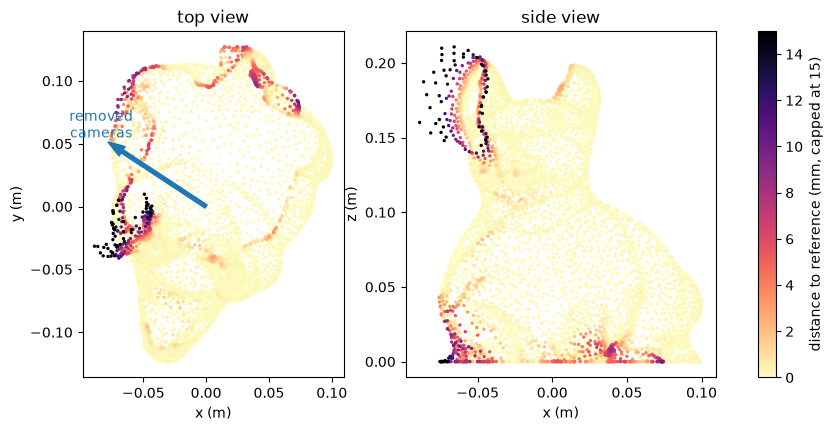

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
order = np.argsort(extra)   # draw large errors on top
for a, (i, j, xl, yl) in zip(ax, [(0, 1, 'x (m)', 'y (m)'), (0, 2, 'x (m)', 'z (m)')]):
    sc = a.scatter(cand.vertices[order, i], cand.vertices[order, j], c=np.minimum(extra[order] * 1000, 15),
                   s=2, cmap='magma_r', vmin=0, vmax=15)
    a.set(xlabel=xl, ylabel=yl, aspect='equal')
ax[0].arrow(0, 0, *(cam_dir * 0.08), width=0.003, color='tab:blue')
ax[0].text(*(cam_dir * 0.1), 'removed\ncameras', color='tab:blue', ha='center')
ax[0].set_title('top view'); ax[1].set_title('side view')
fig.colorbar(sc, ax=ax, label='distance to reference (mm, capped at 15)')
plt.show()

## Collision hulls and physical properties

Same CoACD settings as 01, run separately on each mesh. Mass and centre of mass come from the hulls (the visual mesh has no mass), so this is where geometry error becomes a physics difference.

CoACD has randomness (a seed). To see how much of any difference comes from the decomposition rather than the scan, the reference is also decomposed a second time with seed 1. Each version's files go to `assets/<name>/` with a `scene.xml` that `view.py` can open.

In [6]:
def scene_xml(n_hulls, euler=(0, 0, 0), pos=(0, 0, DROP_HEIGHT)):
    """One dog on a floor. Paths are relative to the dog's folder."""
    hull_assets = ''.join(f'<mesh name="h{i}" file="hull_{i}.obj"/>' for i in range(n_hulls))
    hull_geoms = ''.join(f'<geom type="mesh" mesh="h{i}" density="{DENSITY}" friction="{FRICTION}" '
                         f'rgba="1 0 0 0.5" group="3"/>' for i in range(n_hulls))
    return f'''<mujoco>
  <asset><mesh name="vis" file="visual.obj" inertia="shell"/>{hull_assets}</asset>
  <worldbody>
    <light pos="0 0 2"/>
    <geom type="plane" size="1 1 .1" rgba=".8 .8 .8 1"/>
    <body name="dog" pos="{pos[0]} {pos[1]} {pos[2]}" euler="{euler[0]} {euler[1]} {euler[2]}">
      <freejoint/>
      <geom type="mesh" mesh="vis" contype="0" conaffinity="0" density="0" rgba=".6 .5 .4 1"/>
      {hull_geoms}
    </body>
  </worldbody>
</mujoco>'''

# control: the SAME reference mesh decomposed again with a different CoACD seed
builds = {'reference': ('reference', 0), 'side40': ('side40', 0), 'reference seed 1': ('reference', 1)}

n_hulls, models = {}, {}
for name, (mesh_name, seed) in builds.items():
    body = bodies[mesh_name]
    folder = ASSET_DIR / name.replace(' ', '_')
    folder.mkdir(parents=True, exist_ok=True)
    body.export(folder / 'visual.obj')
    parts = coacd.run_coacd(coacd.Mesh(body.vertices, body.faces), threshold=COACD_THRESHOLD, seed=seed)
    for i, (v, f) in enumerate(parts):
        trimesh.Trimesh(v, f).export(folder / f'hull_{i}.obj')
    n_hulls[name] = len(parts)
    (folder / 'scene.xml').write_text(scene_xml(len(parts)))
    models[name] = mujoco.MjModel.from_xml_path(str(folder / 'scene.xml'))

print(f'{"":17} {"hulls":>6} {"hull volume":>12} {"mass":>8}   centre of mass (x, y, z) cm')
for name, m in models.items():
    vol = m.body_mass[1] / DENSITY
    print(f'{name:17} {n_hulls[name]:6d} {vol * 1e6:9.0f} cm3 {m.body_mass[1] * 1000:6.0f} g   '
          f'{(m.body_ipos[1] * 100).round(2)}')

                   hulls  hull volume     mass   centre of mass (x, y, z) cm
reference             67       748 cm3   1121 g   [ 0.02 -0.2   7.9 ]
side40                67       808 cm3   1212 g   [-0.28 -0.41  8.25]
reference seed 1      68       733 cm3   1100 g   [-0.08 -0.24  7.95]


## Drop test from random orientations

Notebook 01 dropped one dog once. Here both dogs are dropped from the same 50 random starting orientations, and for each drop I record which way the dog ends up resting. "Down" is the dog's own direction that points at the floor at the end: (0, 0, -1) means upright on its cut base.

Two controls, because side40 only shows a real effect if it differs from the reference by more than these do:

- **nudged**: the reference dropped again from each orientation turned by 0.5 deg. Tumbling can be chaotic; this measures how much.
- **seed 1**: the same reference mesh with hulls from a different CoACD seed. This measures how much the collision decomposition alone changes the outcome.

In [7]:
rotations = Rotation.random(N_DROPS, SEED)
rng = np.random.default_rng(SEED)
axes = rng.normal(size=(N_DROPS, 3)); axes /= np.linalg.norm(axes, axis=1, keepdims=True)
nudged = [Rotation.from_rotvec(a * np.radians(NUDGE_DEG)) * r for a, r in zip(axes, rotations)]

def drop(name, rot):
    m = models[name]
    d = mujoco.MjData(m)
    d.qpos[3:7] = np.roll(rot.as_quat(), 1)          # scipy x y z w -> mujoco w x y z
    mujoco.mj_forward(m, d)
    still = 0.0
    while d.time < MAX_SECONDS and still < 0.5:      # settled = barely moving for 0.5 s
        mujoco.mj_step(m, d)
        still = still + m.opt.timestep if np.linalg.norm(d.qvel) < 1e-3 else 0.0
    R = d.xmat[1].reshape(3, 3)
    return dict(down=R.T @ [0, 0, -1],              # floor direction, in the dog's own frame
                settled=still >= 0.5, time=d.time)

runs = {'reference': [drop('reference', r) for r in rotations],
        'side40': [drop('side40', r) for r in rotations],
        'reference nudged': [drop('reference', r) for r in nudged],
        'reference seed 1': [drop('reference seed 1', r) for r in rotations]}

for name, rs in runs.items():
    print(f'{name:17} settled {sum(r["settled"] for r in rs)}/{N_DROPS}, '
          f'median {np.median([r["time"] for r in rs]):.1f} s')

reference         settled 50/50, median 2.8 s
side40            settled 50/50, median 2.3 s
reference nudged  settled 50/50, median 2.8 s
reference seed 1  settled 50/50, median 2.7 s


In [8]:
down = {k: np.array([r['down'] for r in rs]) for k, rs in runs.items()}
angle = lambda a, b: np.degrees(np.arccos(np.clip((a * b).sum(1), -1, 1)))
diffs = {'side40': angle(down['reference'], down['side40']),                  # effect + noise
         'nudged': angle(down['reference'], down['reference nudged']),        # chaos only
         'seed 1': angle(down['reference'], down['reference seed 1'])}        # decomposition only
ok = np.all([[r['settled'] for r in rs] for rs in runs.values()], axis=0)

upright = down['reference'][:, 2] < -0.98
toward = down['reference'][:, :2] @ cam_dir > 0.5 * np.linalg.norm(down['reference'][:, :2], axis=1)
groups = {'upright on cut base': upright, 'lying on error side': ~upright & toward,
          'lying elsewhere': ~upright & ~toward}

print(f'{ok.sum()}/{N_DROPS} orientations where every drop settled (others left out)\n')

def bins(d):
    return [(d < 2).sum(), ((d >= 2) & (d < 25)).sum(), (d >= 25).sum()]

print(f'{"vs reference":30} {"identical":>10} {"tilted":>8} {"other face":>11}   (out of {ok.sum()})')
print(f'{"":30} {"(<2 deg)":>10} {"(2-25)":>8} {"(>25 deg)":>11}')
for key, label in [('nudged', 'control: start nudged 0.5 deg'), ('seed 1', 'control: other CoACD seed'),
                   ('side40', 'side40')]:
    print(f'{label:30} ' + ''.join(f'{x:>{w}}' for x, w in zip(bins(diffs[key][ok]), (10, 8, 11))))

print('\nside40, split by how the reference landed:')
for label, mask in groups.items():
    mask = mask & ok
    i, t, f = bins(diffs['side40'][mask])
    tilted = diffs['side40'][mask & (diffs['side40'] >= 2) & (diffs['side40'] < 25)]
    print(f'  {label:22} n={mask.sum():2d}: identical {i:2d}, tilted {t:2d}, other face {f:2d}'
          + (f'  (tilts {np.median(tilted):.1f} deg median)' if len(tilted) else ''))

50/50 orientations where every drop settled (others left out)

vs reference                    identical   tilted  other face   (out of 50)
                                 (<2 deg)   (2-25)   (>25 deg)
control: start nudged 0.5 deg          49       0          1
control: other CoACD seed              46       0          4
side40                                 16      19         15

side40, split by how the reference landed:
  upright on cut base    n= 4: identical  4, tilted  0, other face  0
  lying on error side    n=14: identical  0, tilted  8, other face  6  (tilts 11.1 deg median)
  lying elsewhere        n=32: identical 12, tilted 11, other face  9  (tilts 10.6 deg median)


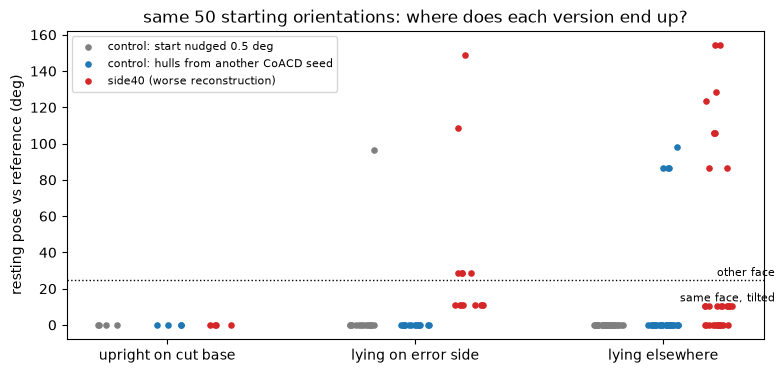

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
styles = {'nudged': ('tab:grey', 'control: start nudged 0.5 deg'),
          'seed 1': ('tab:blue', 'control: hulls from another CoACD seed'),
          'side40': ('tab:red', 'side40 (worse reconstruction)')}
for k, (label, mask) in enumerate(groups.items()):
    mask = mask & ok
    for j, (key, (color, name)) in enumerate(styles.items()):
        jit = np.random.default_rng(10 * k + j).uniform(-0.06, 0.06, mask.sum())
        ax.scatter(k + (j - 1) * 0.22 + jit, diffs[key][mask], s=14, color=color, label=name if k == 0 else None)
ax.axhline(25, color='k', ls=':', lw=1)
ax.text(2.45, 27, 'other face', fontsize=8, ha='right')
ax.text(2.45, 13, 'same face, tilted', fontsize=8, ha='right')
ax.set(xticks=range(3), xticklabels=list(groups), ylabel='resting pose vs reference (deg)',
       title='same 50 starting orientations: where does each version end up?')
ax.legend(loc='upper left', fontsize=8)
plt.show()

## Both dogs in the viewer

Writes `assets/compare.xml`: reference at x = -0.2, side40 at x = +0.2, same starting tilt. Open it with `python view.py compare`; press 3 to toggle the collision hulls.

In [10]:
def dog_body(name, x, euler):
    n = n_hulls[name]
    assets = f'<mesh name="{name}_vis" file="{name}/visual.obj" inertia="shell"/>' + ''.join(
        f'<mesh name="{name}_h{i}" file="{name}/hull_{i}.obj"/>' for i in range(n))
    geoms = (f'<geom type="mesh" mesh="{name}_vis" contype="0" conaffinity="0" density="0" rgba=".6 .5 .4 1"/>'
             + ''.join(f'<geom type="mesh" mesh="{name}_h{i}" density="{DENSITY}" friction="{FRICTION}" '
                       f'rgba="1 0 0 0.5" group="3"/>' for i in range(n)))
    body = (f'<body name="{name}" pos="{x} 0 {DROP_HEIGHT}" euler="{euler[0]} {euler[1]} {euler[2]}">'
            f'<freejoint/>{geoms}</body>')
    return assets, body

tilt = (0, 30, 0)   # a start where both dogs tip over
a1, b1 = dog_body('reference', -0.2, tilt)
a2, b2 = dog_body('side40', 0.2, tilt)
(ASSET_DIR / 'compare.xml').write_text(f'''<mujoco><asset>{a1}{a2}</asset><worldbody><light pos="0 0 2"/>
  <geom type="plane" size="1 1 .1" rgba=".8 .8 .8 1"/>{b1}{b2}</worldbody></mujoco>''')
mujoco.MjModel.from_xml_path(str(ASSET_DIR / 'compare.xml'))   # check it loads
print('saved', ASSET_DIR / 'compare.xml')

saved assets/compare.xml


## Results and limitations

**Alignment.** The camera fit is basically exact (0.01% of the camera ring radius), so differences below come from the reconstructions, not the alignment.

**Geometry.** 95% of side40 is within 5 mm of the reference. The error is concentrated in one place: extra surface around one ear, up to 30 mm out, on the side the 20 cameras were removed from (19 deg apart). With no photos of that ear, the reconstruction smeared it outward. That blob makes side40 1.5 cm wider and 1.1 cm taller.

**Physical properties.** The extra volume gives side40 about 7% more mass (1166 vs 1092 g). Centre of mass moves about 4 mm.

**Drops (50 random orientations).**

- Both controls end in the identical pose in 48/50 drops. The other 2 flip for both controls too, so those starts are just chaotic.
- side40 is identical in only 12/50. All 4 upright landings match (the flat cut base decides those).
- When lying down, side40 is either tilted by about 11 deg on the same face (23 drops) or on a different face entirely (15 drops). The tilt is consistent with the ear blob propping the body up, but I haven't checked the contact points to confirm that.
- So the reconstruction error changes the resting pose in 38/50 drops, while hull randomness and small changes to the start almost never do.

**Limitations.**

- Height (0.20 m) and density are assumed, and the flat cut base isn't the real object's base.
- One object and one kind of error (one side not photographed).
- Only the resting pose after a drop. Grasping or pushing would test more; `grasp_test.py` is a start but not validated yet.
- No real drop to compare against. This shows the two simulations disagree, not which one matches reality. The reference is assumed to be closer to the truth because it used all 50 photos.
- CoACD output differs between machines (side40 got 67 hulls on macOS, 71 on Linux), so exact numbers can shift a little when rerun. The seed control suggests it doesn't change the conclusion.